In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [1]:
import cv2

import numpy as np

import matplotlib.pyplot as plt


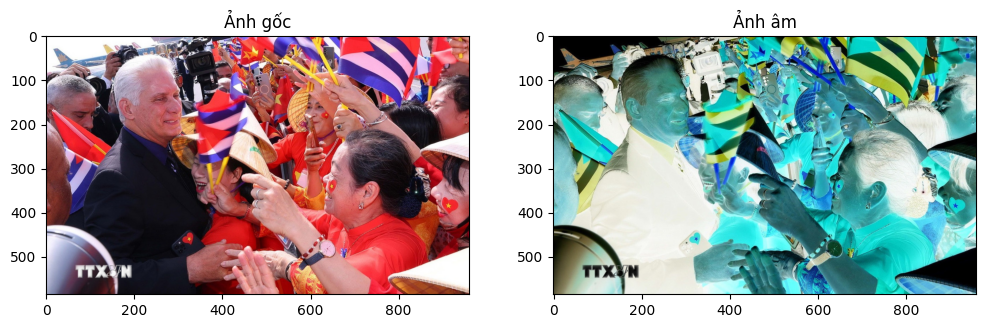

In [2]:
# cac phep bien doi cuong do sang (Intensity transfomation)

# negative image(anh am)
# công thức: s = L - 1 - r
# L: giá trị xám tối đa
# r: giá trị của pixel hiện tại
# s: giá trị pixel sau khi biến đổi
img = cv2.imread('c:/CS/image_processing/Tieu_Luan_1/demo.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
negativeImg = 255 - img

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Ảnh gốc')
axes[1].imshow(negativeImg, cmap='gray')
axes[1].set_title('Ảnh âm')
plt.show()

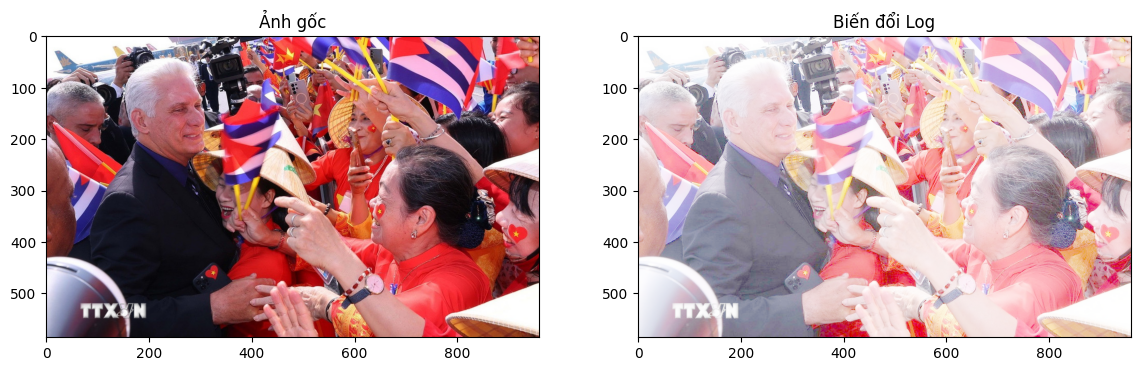

In [3]:
# biến đổi logarithm


def log_transform(img, c):
  # chuyen anh ve float
  img_float = img.astype(np.float64)

  # tinh log
  log_img = c * np.log(1 + img_float)

  # chuẩn hóa về[0, 255]
  log_img = np.uint8(255 * (log_img) / np.max(log_img))

  fig, axes = plt.subplots(1, 2, figsize=(14, 7))
  axes[0].imshow(img, cmap='gray')
  axes[0].set_title('Ảnh gốc')
  axes[1].imshow(log_img, cmap='gray')
  axes[1].set_title('Biến đổi Log')
  plt.show()

  return log_img

c = 1 # hằng số điều chỉnh
logImg = log_transform(img, c)

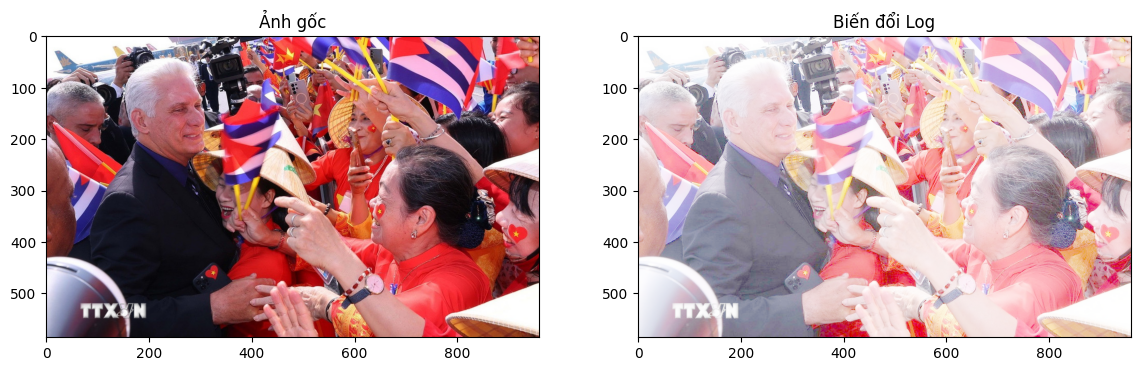

In [4]:
# biến đổi logarithm


def log_transform1(img, c):
  # chuyen anh ve float
  img_float = img.astype(np.float64)

  # tinh log
  log_img = c * np.log(1 + img_float)

  # chuẩn hóa về[0, 255]
  log_img = np.uint8(255 * (log_img) / np.max(log_img))


  return log_img

c = 1 # hằng số điều chỉnh
logImg = log_transform(img, c)

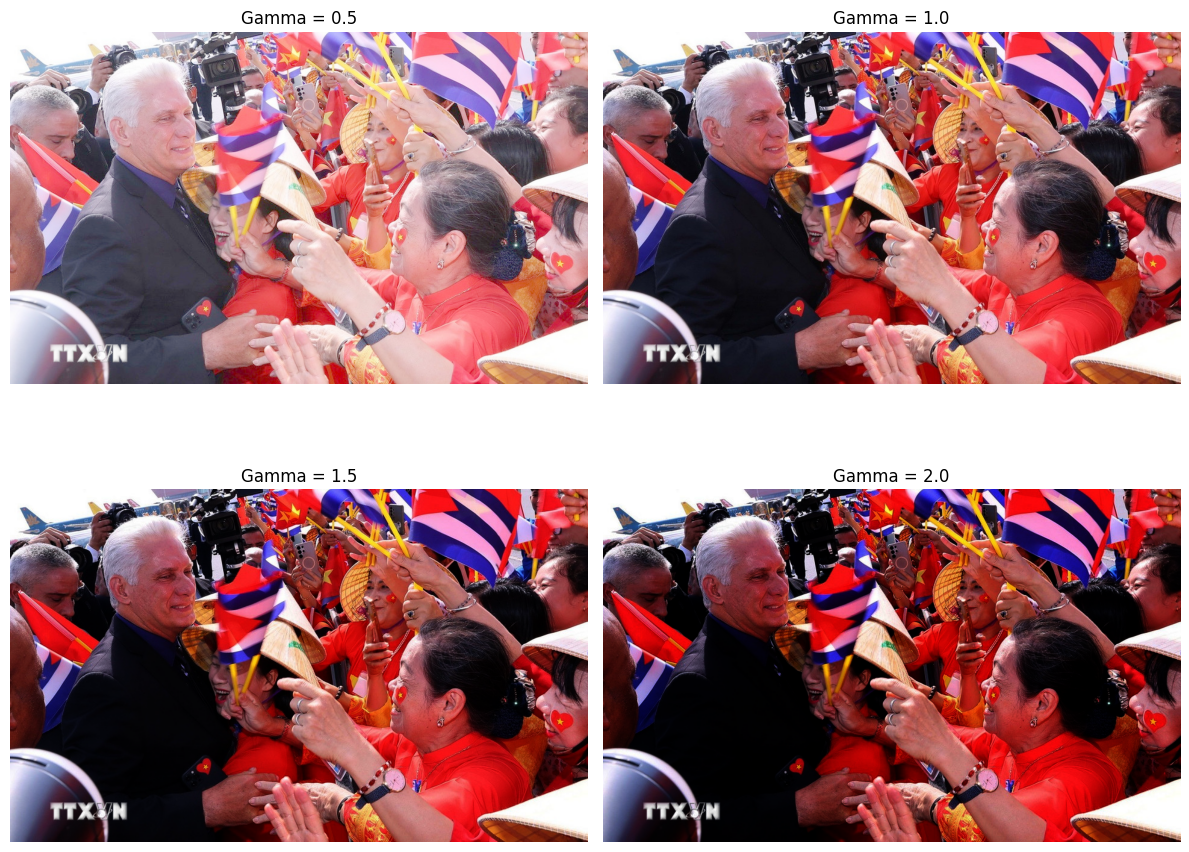

In [5]:
# power law - gamma correction
#  công thức: s = c * r^gamma
#  với:
#  gamma > 1: làm tối Ảnh
#  gamma < 1: làm sáng ảnh


def gamma_correction(img, gamma):

  # chuẩn hóa về [0, 1]
  img_normalized = img / 255.0
  corrected = c * np.power(img_normalized, gamma)

  # chuẩn hóa về [0, 255]
  corrected = np.uint8(corrected * 255)

  return corrected


gammas = [0.5, 1.0, 1.5, 2.0]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, gamma in enumerate(gammas):
    gamma_img = gamma_correction(img, gamma)
    axes[i].imshow(gamma_img, cmap='gray')
    axes[i].set_title(f'Gamma = {gamma}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()


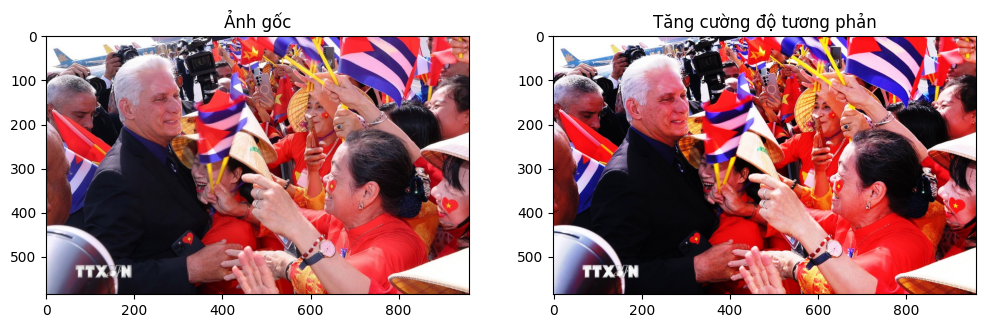

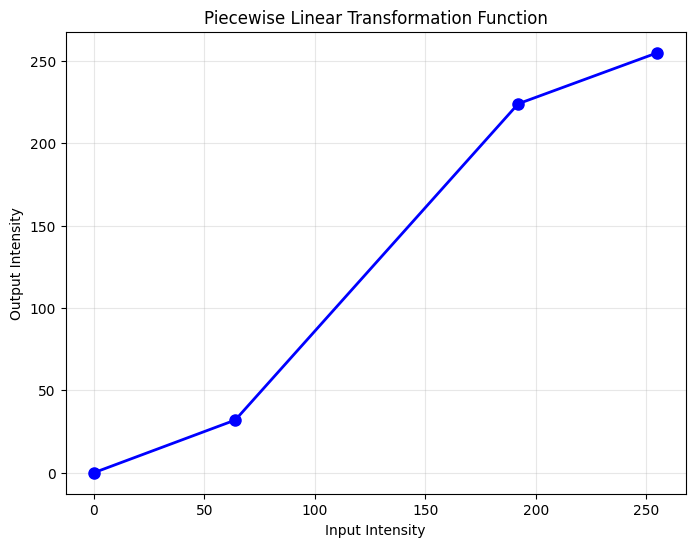

In [6]:
# piecewise tranformation
def piecewise_transform(img, points):
  # tạo bảng lookup table
  lut = np.zeros(256, dtype=np.uint8)
  # sắp xếp các điểm theo thứ tự tăng dần
  points = sorted(points)

  # tính toán
  for i in range(len(points) -1):
    x1, y1 = points[i]
    x2, y2 = points[i+1]
    if x1 == x2:
       lut[x1] = np.clip(y1, 0, 255)
    else:
      # nội suy tuyến tính trong đoạn [x1, x2]
          for x in range(x1, x2 + 1):
              y = y1 + (y2 - y1) * (x - x1) / (x2 - x1)
              lut[x] = np.clip(int(y), 0, 255)
  return cv2.LUT(img, lut)

  # Ví dụ: Tăng cường độ tương phản
contrast_points = [(0, 0), (64, 32), (192, 224), (255, 255)]
contrast_img = piecewise_transform(img, contrast_points)

# Hiển thị
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Ảnh gốc')
axes[1].imshow(contrast_img, cmap='gray')
axes[1].set_title('Tăng cường độ tương phản')
plt.show()

# Vẽ đồ thị transformation function
x = np.array([p[0] for p in contrast_points])
y = np.array([p[1] for p in contrast_points])
plt.figure(figsize=(8, 6))
plt.plot(x, y, 'b-o', linewidth=2, markersize=8)
plt.xlabel('Input Intensity')
plt.ylabel('Output Intensity')
plt.title('Piecewise Linear Transformation Function')
plt.grid(True, alpha=0.3)
plt.show()


Cân bằng lược đồ mức xám (histogram equalization)

C:\Users\ngova\AppData\Local\Temp\ipykernel_14584\3553829481.py:43: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, 0].hist(gray_image.flatten(), 256, [0, 256], alpha=0.7)
C:\Users\ngova\AppData\Local\Temp\ipykernel_14584\3553829481.py:49: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, 1].hist(eq_manual.flatten(), 256, [0, 256], alpha=0.7)
C:\Users\ngova\AppData\Local\Temp\ipykernel_14584\3553829481.py:55: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, 2].hist(eq_opencv.flatten(), 256, [0, 256], alpha=0.7)
C:\Users\ngova\AppData\Local\Temp\ipykernel_14584\3553829481.py:55: MatplotlibDeprecationWarning: Pass

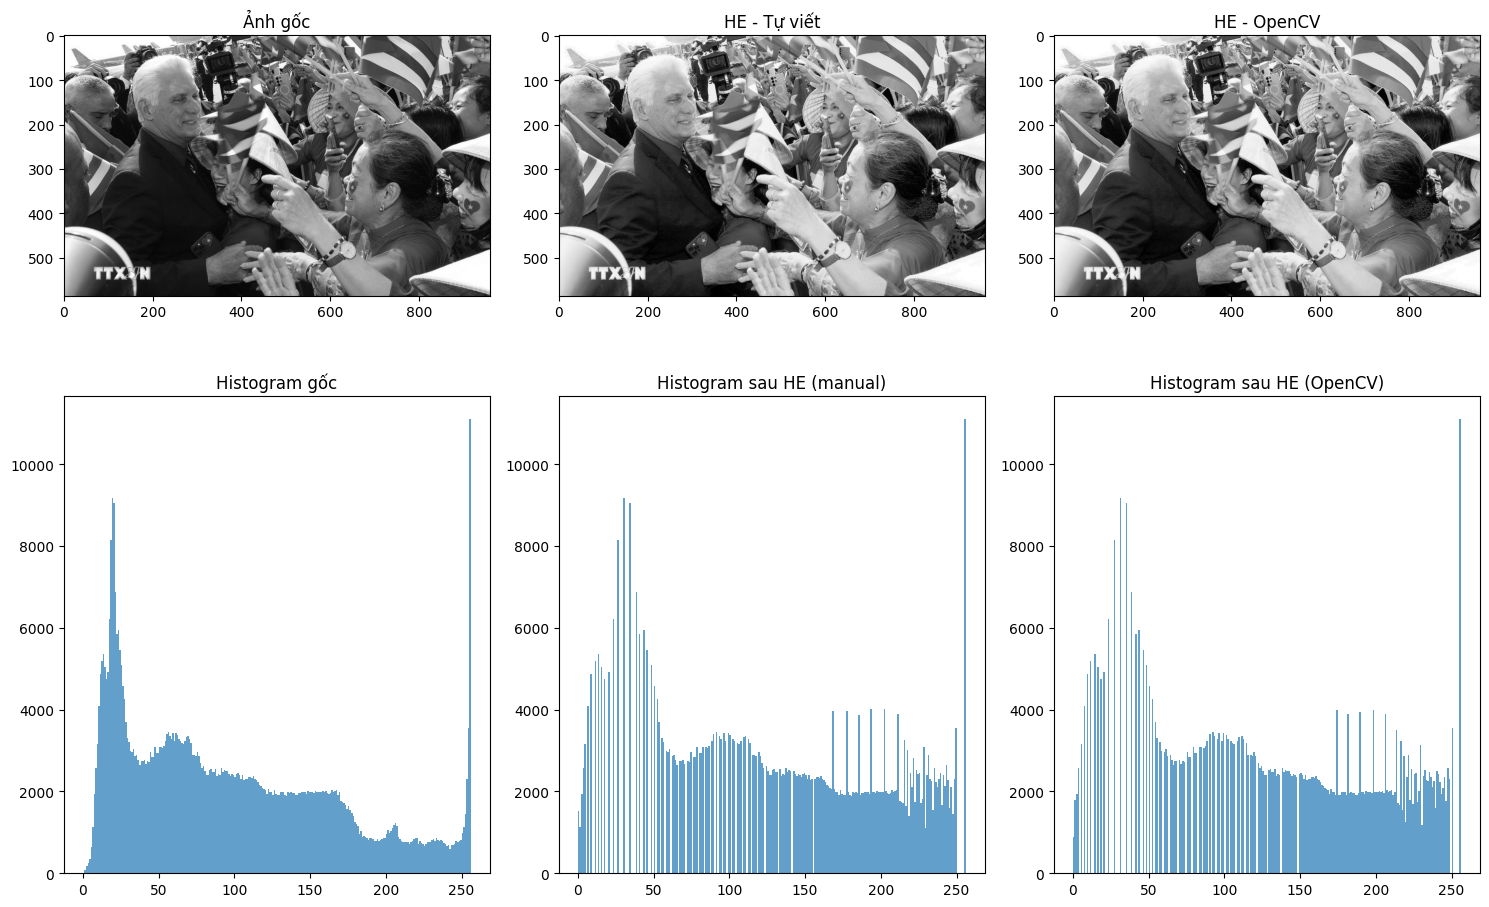

In [10]:
# 2.1.1 histogram equalization toàn cục
def histogram_equalization(img):
    # Convert to grayscale if not already
    if len(img.shape) == 3:
        gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray_img = img.copy()

    # tạo histogram
    hist, bins = np.histogram(gray_img.flatten(), 256, [0, 256])

    # tính cdf
    cdf =  hist.cumsum()
    # chuẩn hóa cdf
    cdf_normalized = cdf * 255 / cdf[-1]

    # áp dụng transformation
    equalized = np.interp(gray_img.flatten(), bins[:-1], cdf_normalized)

    return equalized.reshape(gray_img.shape).astype(np.uint8)

# So sánh với OpenCV
def compare_histogram_methods(image):
    # Convert to grayscale if not already
    if len(image.shape) == 3:
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray_image = image.copy()


    # Tự viết
    eq_manual = histogram_equalization(gray_image)

    # OpenCV
    eq_opencv = cv2.equalizeHist(gray_image)

    # Hiển thị
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Ảnh gốc
    axes[0, 0].imshow(gray_image, cmap='gray')
    axes[0, 0].set_title('Ảnh gốc')
    axes[1, 0].hist(gray_image.flatten(), 256, [0, 256], alpha=0.7)
    axes[1, 0].set_title('Histogram gốc')

    # Manual
    axes[0, 1].imshow(eq_manual, cmap='gray')
    axes[0, 1].set_title('HE - Tự viết')
    axes[1, 1].hist(eq_manual.flatten(), 256, [0, 256], alpha=0.7)
    axes[1, 1].set_title('Histogram sau HE (manual)')

    # OpenCV
    axes[0, 2].imshow(eq_opencv, cmap='gray')
    axes[0, 2].set_title('HE - OpenCV')
    axes[1, 2].hist(eq_opencv.flatten(), 256, [0, 256], alpha=0.7)
    axes[1, 2].set_title('Histogram sau HE (OpenCV)')

    plt.tight_layout()
    plt.show()

histogram = compare_histogram_methods(img)

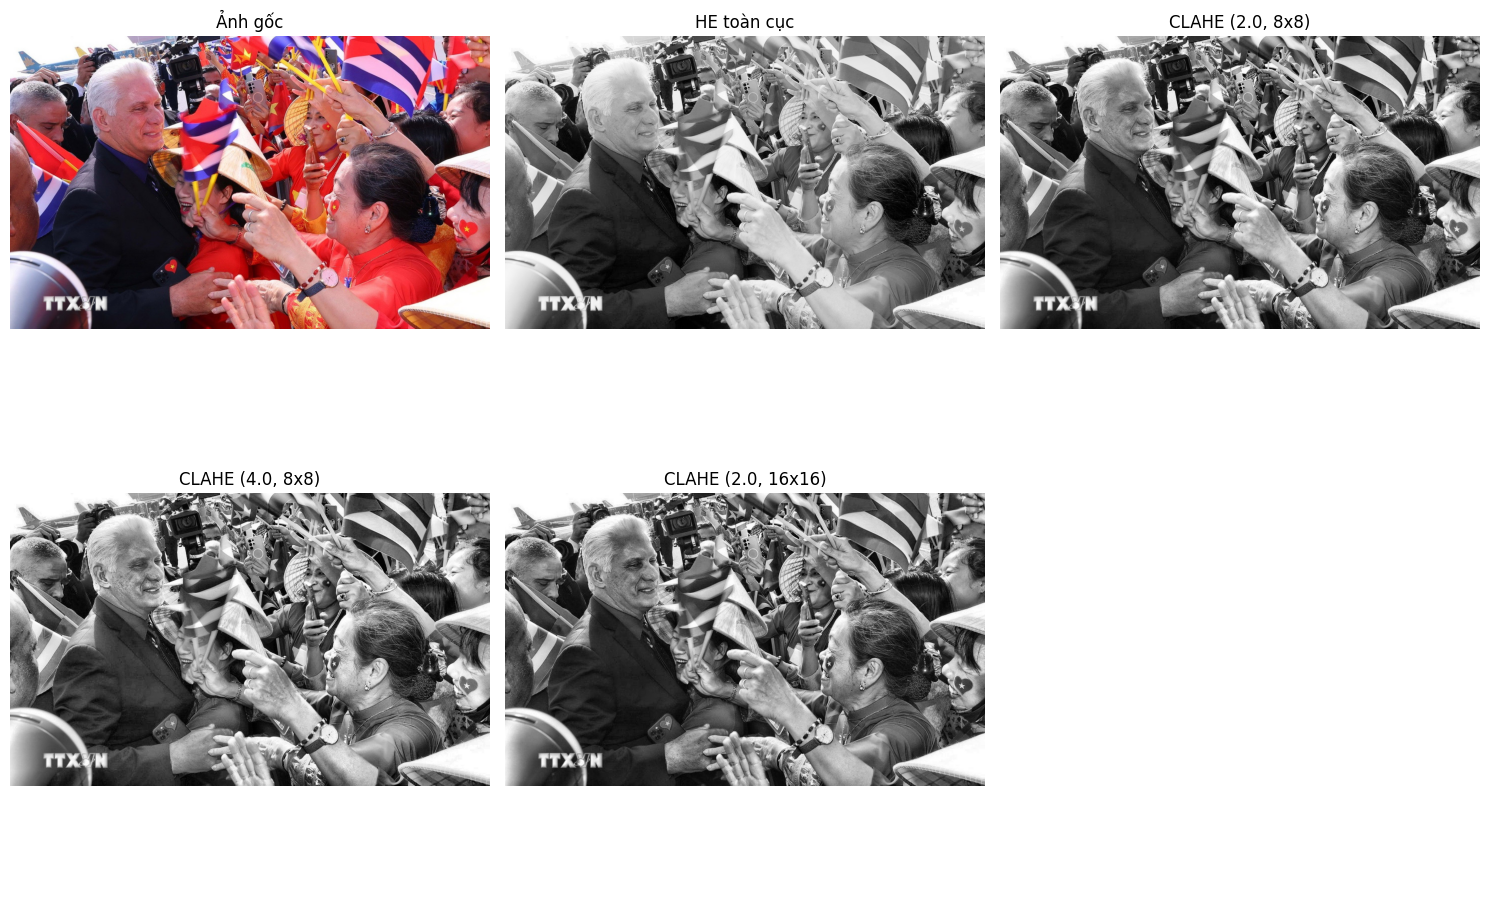

In [11]:
# 2.1.2 CLAHE
def apply_clahe(img, clip_limit, title_grid_size):
  if len(img.shape) == 3:
      gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  else:
      gray_img = img.copy()
  clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize =title_grid_size)
  return clahe.apply(gray_img)

def compare_equalization_methods(img):
  if len(img.shape) == 3:
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  else:
    gray_img = img.copy()
  eq_global = cv2.equalizeHist(gray_img)

  #  tao nhieu CLAHE voi tham so khac nhau
  clahe1 = apply_clahe(img, 2.0, (8, 8))
  clahe2 = apply_clahe(img, 4.0, (8, 8))
  clahe3 = apply_clahe(img, 2.0, (16, 16))

  images = [img, eq_global, clahe1, clahe2, clahe3]
  titles = ['Ảnh gốc', 'HE toàn cục', 'CLAHE (2.0, 8x8)',
              'CLAHE (4.0, 8x8)', 'CLAHE (2.0, 16x16)']

  fig, axes = plt.subplots(2, 3, figsize=(15, 10))
  axes = axes.flatten()

  for i, (img_proc, title) in enumerate(zip(images, titles)):
      if i < len(axes):
          axes[i].imshow(img_proc, cmap='gray')
          axes[i].set_title(title)
          axes[i].axis('off')

  # Ẩn subplot thừa
  if len(axes) > len(images):
      axes[-1].axis('off')

  plt.tight_layout()
  plt.show()



clahe_result = compare_equalization_methods(img)

Ứng dụng biến đổi ảnh trong thực tế


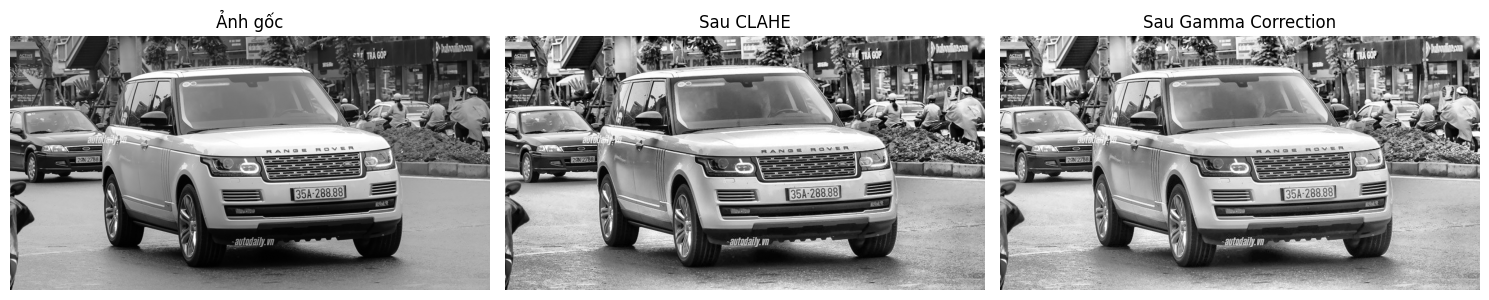

In [ ]:
# tiền xử lí ảnh trong nhận dạng biển số xe
def tienXuLyBSX(img):
  # Chuyển sang hình xám
  if len(img.shape) == 3: # Check if the image is color
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  else:
    gray = img.copy()

  # Ensure the image is 8-bit single channel
  if gray.dtype != np.uint8:
      gray = gray.astype(np.uint8)

#  áp dụng clahe để tăng độ tương phản
  clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
  enhanced = clahe.apply(gray)

  # gamma corection để tăng độ sáng
  gamma_corrected = gamma_correction(enhanced, 0.8)

  return {

        'original': gray,
        'enhanced': enhanced,
        'gamma_corrected': gamma_corrected
    }

def hienThiBSX(img_paths):

  results = []
  for path in img_paths:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
      print(f"Không thể đọc ảnh: {path}") # Khi không đọc được ảnh
      continue
    result = tienXuLyBSX(img)
    results.append(result)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes = axes.flatten()
    titles = ['Ảnh gốc', 'Sau CLAHE', 'Sau Gamma Correction']
    keys = ['original', 'enhanced', 'gamma_corrected']

    for i, (key, title) in enumerate(zip(keys, titles)):
            axes[i].imshow(result[key], cmap='gray')
            axes[i].set_title(title)
            axes[i].axis('off')

    plt.tight_layout()
    plt.show()

img_paths = ['C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\biensoxe.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx2.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx3.jpg',
             'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx4.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx5.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx6.jpg', 
             'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx7.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx8.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx9.jpg', 
             'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_bien_so_xe\\bsx10.jpg']

hienThiBSX(img_paths)




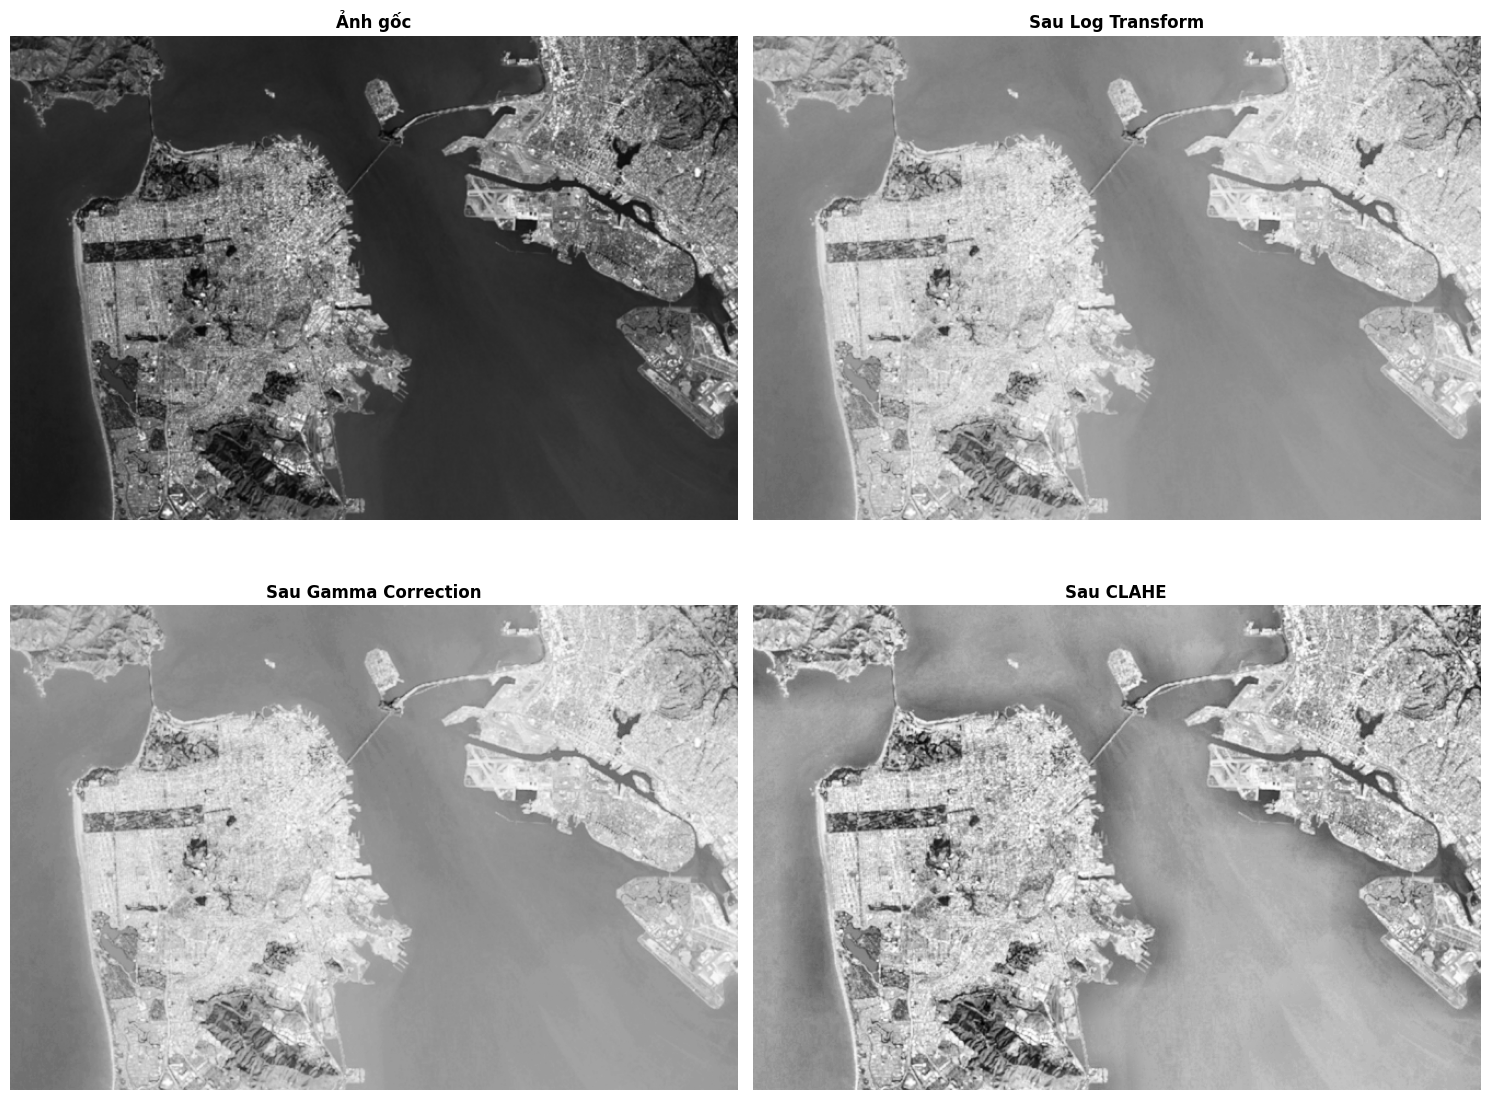

In [ ]:
def caiThienAnhVeTinh(img):
  #log transform để cải thiện vùng tối
  log_enhanced = log_transform1(img, 1.5)
  #gamma corection để tăng độ sáng
  gamma_enhanced = gamma_correction(log_enhanced, 0.8)

  #CLAHE để cải thiện độ tương phản local
  clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(16, 16))
  final_enhanced = clahe.apply(gamma_enhanced)
  return {
      'original': img,
      'log_enhanced': log_enhanced,
      'gamma_corrected': gamma_enhanced,
      'clahe': final_enhanced
  }

def hienThiNhieuAnhVeTinh(image_paths):
  results = []
  for idx, path in enumerate(image_paths):
      img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
      if img is None:
          print(f"Không thể đọc ảnh: {path}")
          continue

      result = caiThienAnhVeTinh(img)
      results.append(result)

  # Hiển thị tất cả ảnh sau khi xử lý xong
  for idx, result in enumerate(results):
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        axes = axes.flatten()

        titles = ['Ảnh gốc', 'Sau Log Transform', 'Sau Gamma Correction', 'Sau CLAHE']
        keys = ['original', 'log_enhanced', 'gamma_corrected', 'clahe']

        for i, (key, title) in enumerate(zip(keys, titles)):
            axes[i].imshow(result[key], cmap='gray')
            axes[i].set_title(title, fontsize=12, fontweight='bold')
            axes[i].axis('off')

        plt.tight_layout()
        plt.show()

img_paths = (['C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\anhvetinh.jpeg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt2.png', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt3.png',
               'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt4.png', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt5.png', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt6.png',
               'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt7.png', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt8.png', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt9.png',
               'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_ve_tinh\\avt10.png'])
hienThiNhieuAnhVeTinh(img_paths)

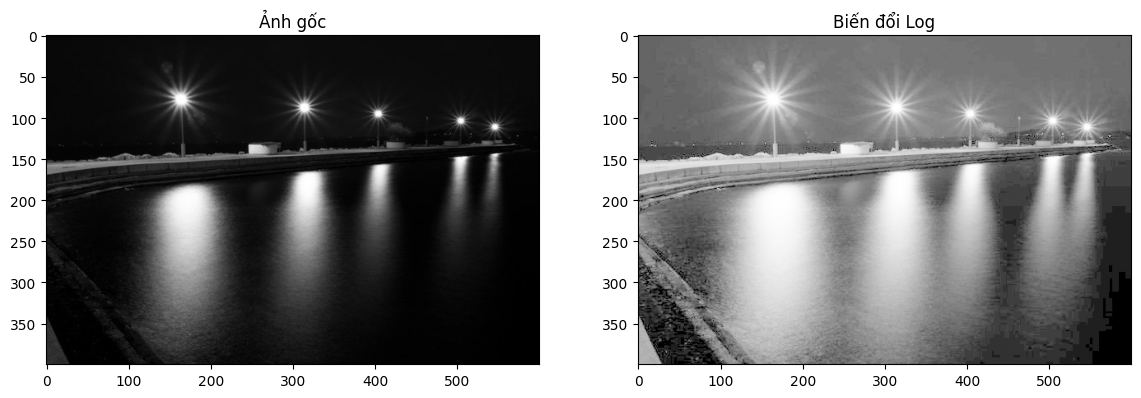

In [ ]:
# cải thiện ảnh tối
def caiThienAnhToi(img):

    # 1. Log transformation để nâng vùng tối
    log_img = log_transform(img, c=2)

    # 2. Gamma correction để điều chỉnh
    gamma_img = gamma_correction(log_img, gamma=0.7)

    # 3. CLAHE để cải thiện detail
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gamma_img)

    return enhanced

def xuLyNhieuAnhToi(img_paths):

    results = []

    for path in img_paths:
        # Đọc ảnh
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue

        # Xử lý
        enhanced = caiThienAnhToi(img)

        # Lưu kết quả
        results.append({
            'path': path,
            'original': img,
            'enhanced': enhanced
        })

    return results

results = xuLyNhieuAnhToi(['C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\anhAnhSangKem.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask2.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask3.jpg',
                           'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask4.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask5.jpg','C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask6.jpg',
                            'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask7.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask8.jpg',
                            'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask9.jpg', 'C:\\CS\\image_processing\\Tieu_Luan_1\\anh_anh_sang_kem\\ask10.jpg' ])